<a href="https://colab.research.google.com/github/SumaiyaObayed/weather-condition-classification-ml/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Importing Dataset**

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pandas import Timestamp
import itertools
from IPython.display import display, HTML
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree  import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score
from sklearn.metrics import classification_report
import warnings
warnings.filterwarnings('ignore')

**Loading Dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
Data= pd.read_csv("/content/drive/MyDrive/MSc project file/Final_weather_dataset.csv")

In [ ]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11873 entries, 0 to 11872
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               11873 non-null  object 
 1   datetime           11873 non-null  object 
 2   temp               11873 non-null  float64
 3   feelslike          11873 non-null  float64
 4   dew                11873 non-null  float64
 5   humidity           11873 non-null  float64
 6   precipitation      11873 non-null  float64
 7   windgust           11873 non-null  float64
 8   windspeed          11873 non-null  float64
 9   winddir            11873 non-null  float64
 10  sealevepressure    11597 non-null  float64
 11  cloudcover         11873 non-null  float64
 12  visibility         11787 non-null  float64
 13  Weather Condition  11597 non-null  object 
dtypes: float64(11), object(3)
memory usage: 1.3+ MB


In [ ]:
Data.shape

(11873, 14)

In [ ]:
Data.head(50)

,name,datetime,temp,feelslike,dew,humidity,precipitation,windgust,windspeed,winddir,sealevepressure,cloudcover,visibility,Weather Condition
0,Dhaka,2015-01-01,21.8,21.8,15.7,70.3,1.7,17.6,11.2,168.0,1013.9,86.1,2.6,"Rain, Partially cloudy"
1,Dhaka,2015-01-02,23.9,24.0,16.5,64.5,1.4,20.9,9.4,117.0,1014.8,65.7,3.2,"Rain, Partially cloudy"
2,Dhaka,2015-01-03,24.2,24.3,17.6,68.0,0.0,13.3,11.2,17.8,1013.7,77.2,3.1,Partially cloudy
3,Dhaka,2015-01-04,23.5,23.6,18.7,75.4,1.3,27.0,18.4,296.4,1011.8,79.4,3.2,"Rain, Partially cloudy"
4,Dhaka,2015-01-05,21.0,21.0,15.1,70.2,0.0,28.4,18.4,299.2,1012.0,43.7,3.8,Partially cloudy
5,Dhaka,2015-01-06,19.6,19.6,11.8,63.2,0.0,22.3,18.4,320.9,1013.4,13.2,3.7,Clear
6,Dhaka,2015-01-07,18.2,18.2,11.8,69.2,0.0,20.5,14.8,303.9,1013.0,20.1,2.5,Partially cloudy
7,Dhaka,2015-01-08,18.2,18.2,12.7,71.9,0.0,20.9,14.8,285.1,1013.0,28.7,2.2,Partially cloudy
8,Dhaka,2015-01-09,17.9,17.9,13.9,78.4,0.1,20.9,11.2,306.4,1013.3,27.9,1.4,"Rain, Partially cloudy"
9,Dhaka,2015-01-10,18.1,18.1,13.0,74.0,0.0,23.0,13.0,315.3,1014.7,20.3,1.7,Partially cloudy


In [ ]:
Data.describe()

,temp,feelslike,dew,humidity,precipitation,windgust,windspeed,winddir,sealevepressure,cloudcover,visibility
count,11873.000000,11873.000000,11873.000000,11873.000000,11873.000000,11873.000000,11873.000000,11873.000000,11597.000000,11873.000000,11787.000000
mean,25.906570,28.568769,21.236343,77.214175,7.065409,27.878851,16.739754,179.764878,1008.583780,53.297018,5.640893
std,3.976767,6.321180,4.659255,9.530936,16.031325,10.162772,10.683515,100.242517,5.211705,32.142644,11.462107
min,11.900000,11.900000,6.700000,35.400000,0.000000,9.400000,0.000000,0.000000,989.100000,0.000000,0.700000
25%,23.200000,23.300000,17.300000,71.100000,0.000000,20.900000,9.400000,95.600000,1004.500000,23.500000,3.600000
50%,27.000000,29.100000,23.000000,78.300000,0.700000,25.600000,14.800000,173.200000,1008.900000,58.000000,4.100000
75%,29.000000,34.100000,25.200000,83.900000,7.500000,32.400000,22.300000,268.000000,1012.900000,82.300000,5.100000
max,33.800000,44.700000,28.400000,98.500000,413.200000,146.500000,244.800000,360.000000,1019.800000,100.000000,1101.400000


**Exploratory Data Analysis(EDA)**



In [ ]:
Data['Weather Condition'].value_counts()

,count
Weather Condition,
"Rain, Partially cloudy",5251
Clear,2476
Partially cloudy,1942
"Rain, Overcast",1790
Rain,124
Overcast,14


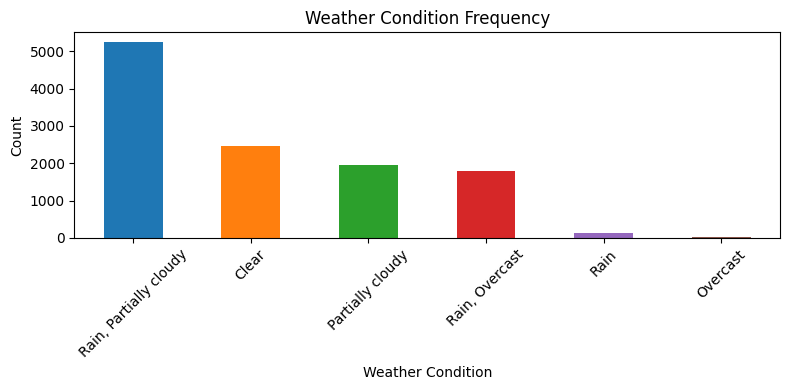

In [ ]:

# Count the occurrences of each weather condition
weather_counts = Data['Weather Condition'].value_counts()

# Plot the bar chart
plt.figure(figsize=(8, 4))
weather_counts.plot(kind='bar', color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f'])
plt.title('Weather Condition Frequency')
plt.xlabel('Weather Condition')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()

# Show the plot
plt.show()


<Figure size 1200x600 with 0 Axes>

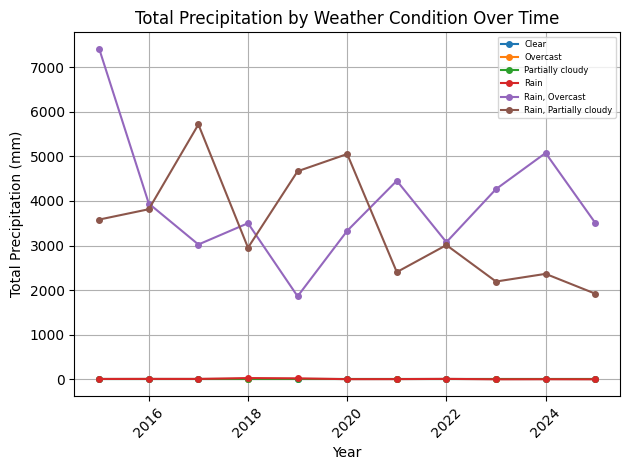

In [ ]:
Data['datetime'] = pd.to_datetime(Data['datetime'])
Data['year'] = Data['datetime'].dt.year

# Group data by year and weather condition and calculate total precipitation for each year and condition
weather_precipitation = Data.groupby(['year', 'Weather Condition'])['precipitation'].sum().unstack()

# Plotting the line graph for each weather condition
plt.figure(figsize=(12, 6))
weather_precipitation.plot(kind='line', marker='o', linestyle='-', markersize=4)

# Customizing the plot
plt.title('Total Precipitation by Weather Condition Over Time')
plt.xlabel('Year')
plt.ylabel('Total Precipitation (mm)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()


plt.legend(
    fontsize=6,
    loc='upper right',
)

plt.show()

**Data Preprocessing**

In [ ]:
Data.isnull().sum()

,0
name,0
datetime,0
temp,0
feelslike,0
dew,0
humidity,0
precipitation,0
windgust,0
windspeed,0
winddir,0


In [ ]:

meanVal_sea = Data['sealevepressure'].mean()
meanVal_vis = Data['visibility'].mean()
mode_value  = Data['Weather Condition'].mode()[0]

#  Missing value fill করা
Data['sealevepressure'].fillna(meanVal_sea, inplace=True)
Data['visibility'].fillna(meanVal_vis, inplace=True)
Data['Weather Condition'].fillna(mode_value, inplace=True)

In [ ]:
Data.isnull().sum()

,0
name,0
datetime,0
temp,0
feelslike,0
dew,0
humidity,0
precipitation,0
windgust,0
windspeed,0
winddir,0


In [ ]:
print(f"Number of duplicates: {Data.duplicated().sum()}")

Number of duplicates: 0


In [ ]:
Data.rename(columns={'name': 'city'}, inplace=True)

In [ ]:
Data.head()

,city,datetime,temp,feelslike,dew,humidity,precipitation,windgust,windspeed,winddir,sealevepressure,cloudcover,visibility,Weather Condition,year
0,Dhaka,2015-01-01,21.8,21.8,15.7,70.3,1.7,17.6,11.2,168.0,1013.9,86.1,2.6,"Rain, Partially cloudy",2015
1,Dhaka,2015-01-02,23.9,24.0,16.5,64.5,1.4,20.9,9.4,117.0,1014.8,65.7,3.2,"Rain, Partially cloudy",2015
2,Dhaka,2015-01-03,24.2,24.3,17.6,68.0,0.0,13.3,11.2,17.8,1013.7,77.2,3.1,Partially cloudy,2015
3,Dhaka,2015-01-04,23.5,23.6,18.7,75.4,1.3,27.0,18.4,296.4,1011.8,79.4,3.2,"Rain, Partially cloudy",2015
4,Dhaka,2015-01-05,21.0,21.0,15.1,70.2,0.0,28.4,18.4,299.2,1012.0,43.7,3.8,Partially cloudy,2015


In [ ]:
#Drop Column
#Data = Data.drop(columns=['datetime'])

In [ ]:
Data.head()

,city,datetime,temp,feelslike,dew,humidity,precipitation,windgust,windspeed,winddir,sealevepressure,cloudcover,visibility,Weather Condition,year
0,Dhaka,2015-01-01,21.8,21.8,15.7,70.3,1.7,17.6,11.2,168.0,1013.9,86.1,2.6,"Rain, Partially cloudy",2015
1,Dhaka,2015-01-02,23.9,24.0,16.5,64.5,1.4,20.9,9.4,117.0,1014.8,65.7,3.2,"Rain, Partially cloudy",2015
2,Dhaka,2015-01-03,24.2,24.3,17.6,68.0,0.0,13.3,11.2,17.8,1013.7,77.2,3.1,Partially cloudy,2015
3,Dhaka,2015-01-04,23.5,23.6,18.7,75.4,1.3,27.0,18.4,296.4,1011.8,79.4,3.2,"Rain, Partially cloudy",2015
4,Dhaka,2015-01-05,21.0,21.0,15.1,70.2,0.0,28.4,18.4,299.2,1012.0,43.7,3.8,Partially cloudy,2015


**Data Encoding**

In [ ]:
data_obj = Data.select_dtypes(['object']).columns

In [ ]:
data_obj

Index(['city', 'Weather Condition'], dtype='object')

In [ ]:
# Encode categorical columns (City & Weather Condition)
from sklearn.preprocessing import LabelEncoder
le_city = LabelEncoder()
le_weather = LabelEncoder()

In [ ]:
Data['city'] = le_city.fit_transform(Data['city'])
Data['Weather Condition'] = le_weather.fit_transform(Data['Weather Condition'])

In [ ]:
cat_code_city = dict(zip(le_city.classes_,[int(i) for i in le_city.transform(le_city.classes_)]))
cat_code_city

{'Chittagong': 0, 'Dhaka': 1, 'Sylhet': 2}

In [ ]:
cat_code_weather = dict(zip(le_weather.classes_,[int(i) for i in le_weather.transform(le_weather.classes_)]))
cat_code_weather

{'Clear': 0,
 'Overcast': 1,
 'Partially cloudy': 2,
 'Rain': 3,
 'Rain, Overcast': 4,
 'Rain, Partially cloudy': 5}

In [ ]:
Data.head(50)

,city,datetime,temp,feelslike,dew,humidity,precipitation,windgust,windspeed,winddir,sealevepressure,cloudcover,visibility,Weather Condition,year
0,1,2015-01-01,21.8,21.8,15.7,70.3,1.7,17.6,11.2,168.0,1013.9,86.1,2.6,5,2015
1,1,2015-01-02,23.9,24.0,16.5,64.5,1.4,20.9,9.4,117.0,1014.8,65.7,3.2,5,2015
2,1,2015-01-03,24.2,24.3,17.6,68.0,0.0,13.3,11.2,17.8,1013.7,77.2,3.1,2,2015
3,1,2015-01-04,23.5,23.6,18.7,75.4,1.3,27.0,18.4,296.4,1011.8,79.4,3.2,5,2015
4,1,2015-01-05,21.0,21.0,15.1,70.2,0.0,28.4,18.4,299.2,1012.0,43.7,3.8,2,2015
5,1,2015-01-06,19.6,19.6,11.8,63.2,0.0,22.3,18.4,320.9,1013.4,13.2,3.7,0,2015
6,1,2015-01-07,18.2,18.2,11.8,69.2,0.0,20.5,14.8,303.9,1013.0,20.1,2.5,2,2015
7,1,2015-01-08,18.2,18.2,12.7,71.9,0.0,20.9,14.8,285.1,1013.0,28.7,2.2,2,2015
8,1,2015-01-09,17.9,17.9,13.9,78.4,0.1,20.9,11.2,306.4,1013.3,27.9,1.4,5,2015
9,1,2015-01-10,18.1,18.1,13.0,74.0,0.0,23.0,13.0,315.3,1014.7,20.3,1.7,2,2015


Checking For Outliers

In [ ]:
numeric_cols = Data.select_dtypes(include=['number']).columns

for col in numeric_cols:
    Q1 = Data[col].quantile(0.25)
    Q3 = Data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = Data[(Data[col] > upper) | (Data[col] < lower)]
    print(f"{col} -> outliers: {outliers.shape[0]}")


city -> outliers: 0
temp -> outliers: 32
feelslike -> outliers: 0
dew -> outliers: 0
humidity -> outliers: 145
precipitation -> outliers: 1300
windgust -> outliers: 415
windspeed -> outliers: 138
winddir -> outliers: 0
sealevepressure -> outliers: 5
cloudcover -> outliers: 0
visibility -> outliers: 1971
Weather Condition -> outliers: 0
year -> outliers: 0


**Feature Selection**

In [ ]:
X = Data.drop(['Weather Condition', 'datetime'], axis=1) # Drop 'datetime' as it's non-numeric
y = Data['Weather Condition']
rfc = RandomForestClassifier() # Initialize rfc
rfe = RFE(rfc, n_features_to_select=10)
rfe = rfe.fit(X, y)

feature_map = [(i, v) for i, v in itertools.zip_longest(rfe.get_support(), X.columns)]
selected_features = [v for i, v in feature_map if i==True]

# User specified to keep 'city' along with selected_features
X = Data[['city'] + selected_features]

top_features = pd.DataFrame({'Features': selected_features})
top_features.index = top_features.index + 1
top_features

,Features
1,temp
2,feelslike
3,dew
4,humidity
5,precipitation
6,windgust
7,winddir
8,sealevepressure
9,cloudcover
10,year


In [ ]:
X

,city,temp,feelslike,dew,humidity,precipitation,windgust,winddir,sealevepressure,cloudcover,year
0,1,21.8,21.8,15.7,70.3,1.7,17.6,168.0,1013.90000,86.1,2015
1,1,23.9,24.0,16.5,64.5,1.4,20.9,117.0,1014.80000,65.7,2015
2,1,24.2,24.3,17.6,68.0,0.0,13.3,17.8,1013.70000,77.2,2015
3,1,23.5,23.6,18.7,75.4,1.3,27.0,296.4,1011.80000,79.4,2015
4,1,21.0,21.0,15.1,70.2,0.0,28.4,299.2,1012.00000,43.7,2015
...,...,...,...,...,...,...,...,...,...,...,...
11868,1,29.5,32.4,22.0,65.3,0.1,18.4,69.7,1008.58378,23.8,2025
11869,1,29.3,32.9,23.5,71.9,0.0,16.6,83.0,1008.58378,62.5,2025
11870,1,27.7,31.0,24.4,82.7,0.4,15.1,340.5,1008.58378,73.4,2025
11871,1,27.6,30.5,24.3,83.2,3.8,24.1,95.6,1008.58378,76.8,2025


Stadard Scaller

In [ ]:
std_scaler = StandardScaler()
X_std = std_scaler.fit_transform(X)
# Convert X_std back to a DataFrame with column names
X = pd.DataFrame(X_std, columns=X.columns)
X_std

array([[-2.99722168e-03, -1.03268377e+00, -1.07085304e+00, ...,
         1.03216532e+00,  1.02058695e+00, -1.57455721e+00],
       [-2.99722168e-03, -5.04594350e-01, -7.22802087e-01, ...,
         1.20690392e+00,  3.85889346e-01, -1.57455721e+00],
       [-2.99722168e-03, -4.29153004e-01, -6.75340593e-01, ...,
         9.93334522e-01,  7.43684564e-01, -1.57455721e+00],
       ...,
       [-2.99722168e-03,  4.50996026e-01,  3.84632778e-01, ...,
         2.20727543e-14,  6.25456579e-01,  1.62172205e+00],
       [-2.99722168e-03,  4.25848911e-01,  3.05530288e-01, ...,
         2.20727543e-14,  7.31239513e-01,  1.62172205e+00],
       [-2.99722168e-03,  7.77908523e-01,  7.01042740e-01, ...,
         2.20727543e-14,  9.65419096e-02,  1.62172205e+00]])

**Data SplitTing**

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,train_size=0.70,random_state=2)

**Model Selection**

Random Forest

Accuracy:  0.9969118472768108
Precision:  0.9949838033948084
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       704
           1       0.00      0.00      0.00         7
           2       0.99      1.00      0.99       592
           3       0.97      1.00      0.99        38
           4       1.00      1.00      1.00       539
           5       1.00      1.00      1.00      1682

    accuracy                           1.00      3562
   macro avg       0.83      0.83      0.83      3562
weighted avg       0.99      1.00      1.00      3562



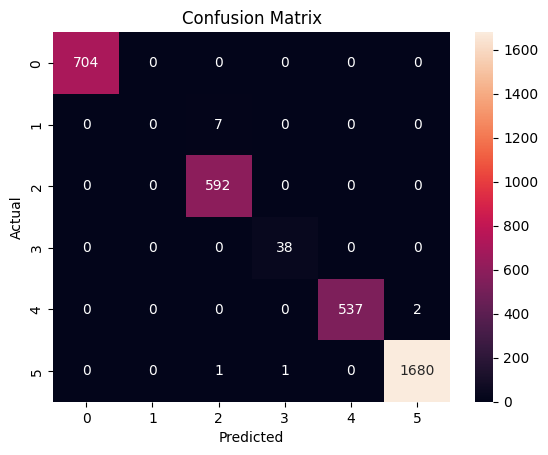

In [ ]:
rf_model = RandomForestClassifier()
rf_model.fit(X_train,y_train)
y_pred_rf = rf_model.predict(X_test)
report = classification_report(y_test, y_pred_rf )

code = """
<pre><code><b>Random Forest</b></code></pre>
"""
display(HTML(code))


print("Accuracy: ", accuracy_score(y_test,y_pred_rf))
print("Precision: ", precision_score(y_test,y_pred_rf, average='weighted'))
print("Classification Report:\n", report)

cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot = True, fmt = 'd')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion Matrix")
plt.show()

XGboost

Accuracy:  0.993542953396968
Precision:  0.9935383313058386
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       704
           1       1.00      1.00      1.00         7
           2       0.99      0.99      0.99       592
           3       0.97      0.97      0.97        38
           4       0.99      0.98      0.99       539
           5       0.99      1.00      0.99      1682

    accuracy                           0.99      3562
   macro avg       0.99      0.99      0.99      3562
weighted avg       0.99      0.99      0.99      3562



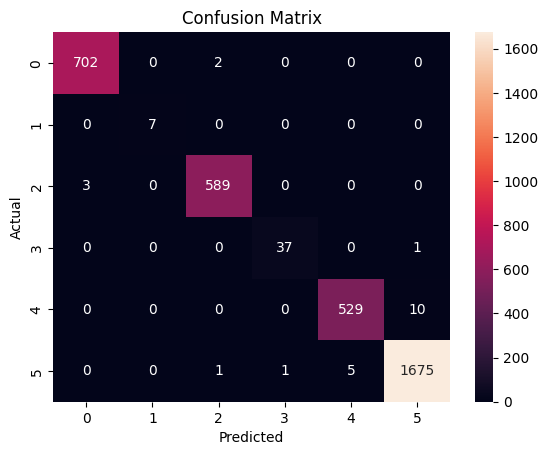

In [ ]:
import xgboost as xgb
xgb_model = xgb.XGBClassifier()
xgb_model.fit(X_train,y_train)
y_pred_xgb = xgb_model.predict(X_test)
report = classification_report(y_test, y_pred_xgb, zero_division=0)

code = """
<pre><code><b>XGBoost Classifier</b></code></pre>
"""
display(HTML(code))


print("Accuracy: ", accuracy_score(y_test,y_pred_xgb))
print("Precision: ", precision_score(y_test,y_pred_xgb, average='weighted',zero_division=0))
print("Classification Report:\n", report)

cm = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm, annot = True, fmt = 'd')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion Matrix")
plt.show()

KNN

Accuracy:  0.8060078607523863
Precision:  0.798767368905956
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.94      0.86       704
           1       0.50      0.14      0.22         7
           2       0.66      0.60      0.63       592
           3       0.17      0.03      0.05        38
           4       0.83      0.78      0.80       539
           5       0.86      0.85      0.85      1682

    accuracy                           0.81      3562
   macro avg       0.63      0.56      0.57      3562
weighted avg       0.80      0.81      0.80      3562



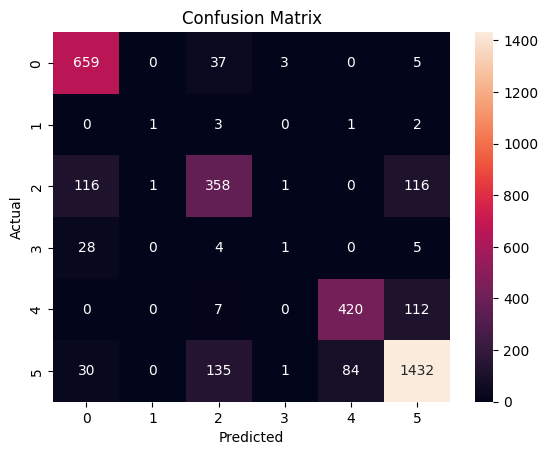

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train,y_train)
y_pred_knn = knn_model.predict(X_test)
report = classification_report(y_test, y_pred_knn )

code = """
<pre><code><b>K-Neighbors Classifier</b></code></pre>
"""
display(HTML(code))


print("Accuracy: ", accuracy_score(y_test,y_pred_knn))
print("Precision: ", precision_score(y_test,y_pred_knn, average='weighted'))
print("Classification Report:\n", report)

cm = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm, annot = True, fmt = 'd')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion Matrix")
plt.show()

SVM

Accuracy:  0.8820887142055025
Precision:  0.8698151873773856
Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.98      0.95       704
           1       0.00      0.00      0.00         7
           2       0.76      0.74      0.75       592
           3       0.00      0.00      0.00        38
           4       0.93      0.93      0.93       539
           5       0.89      0.90      0.90      1682

    accuracy                           0.88      3562
   macro avg       0.58      0.59      0.59      3562
weighted avg       0.87      0.88      0.88      3562



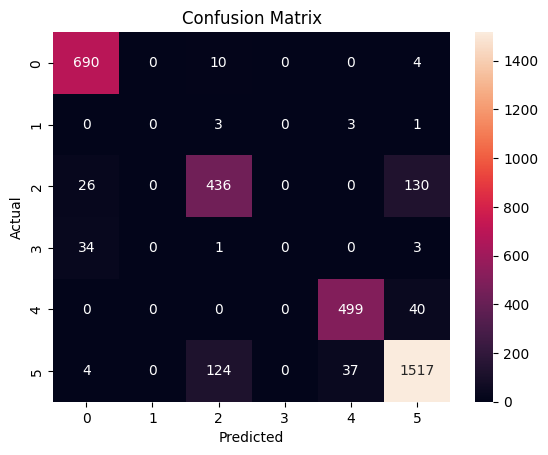

In [ ]:
from sklearn.svm import SVC

svm_model = SVC()
svm_model.fit(X_train,y_train)
y_pred_svm = svm_model.predict(X_test)
report = classification_report(y_test, y_pred_svm, zero_division=0)

code = """
<pre><code><b>Support Vector Machine (SVM)</b></code></pre>
"""
display(HTML(code))


print("Accuracy: ", accuracy_score(y_test,y_pred_svm))
print("Precision: ", precision_score(y_test,y_pred_svm, average='weighted',zero_division=0))
print("Classification Report:\n", report)

cm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm, annot = True, fmt = 'd')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion Matrix")
plt.show()

Accuracy:  0.9789444132509826
Precision:  0.9671139960230397
Classification Report:
               precision    recall  f1-score   support

           0       0.95      1.00      0.98       704
           1       0.00      0.00      0.00         7
           2       1.00      0.99      0.99       592
           3       0.00      0.00      0.00        38
           4       0.95      1.00      0.98       539
           5       0.99      0.99      0.99      1682

    accuracy                           0.98      3562
   macro avg       0.65      0.66      0.66      3562
weighted avg       0.97      0.98      0.97      3562



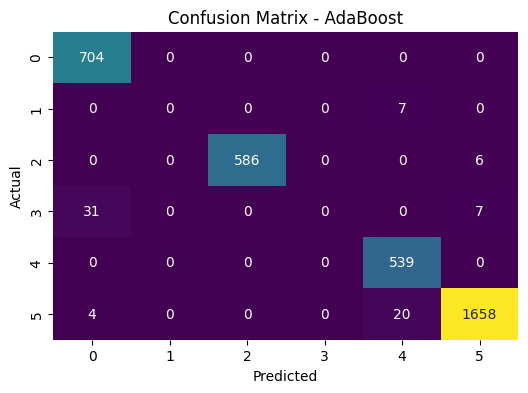

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
ada_model = AdaBoostClassifier()
ada_model.fit(X_train,y_train)
y_pred_ada = ada_model.predict(X_test)
report = classification_report(y_test, y_pred_ada, zero_division=0)


code = """
<pre><code><b>XGBoost Classifier</b></code></pre>
"""
display(HTML(code))


print("Accuracy: ", accuracy_score(y_test, y_pred_ada))
print("Precision: ", precision_score(y_test, y_pred_ada, average='weighted', zero_division=0))
print("Classification Report:\n", report)

# Confusion matrix
cm_ada = confusion_matrix(y_test, y_pred_ada)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_ada, annot=True, fmt='d', cbar=False, cmap='viridis')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion Matrix - AdaBoost")
plt.show()

Evaluation Matrics

In [ ]:
clfs = {'KN' : knn_model,'RF': rf_model, 'AD': ada_model, 'SV' : svm_model, 'XG': xgb_model}
def metrics(clf, X_train, y_train, X_test, y_test):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')

    return accuracy, precision, f1, recall

In [ ]:
accuracy_scores = []
precision_scores = []
f1_scores = []
recall_scores = []

for name, clf in clfs.items():

    x_train,x_test,y_train,y_test = train_test_split(X_std,y, test_size = 0.2, random_state = 42)
    current_accuracy, current_precision, current_f1, current_recall = metrics(clf, x_train, y_train, x_test, y_test)

    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)
    f1_scores.append(current_f1)
    recall_scores.append(current_recall)

performance_df = pd.DataFrame({'Algorithm':clfs.keys(), 'Accuracy':accuracy_scores,'Precision':precision_scores,'F1-score':f1_scores,'Recall':recall_scores}).sort_values(by='Accuracy', ascending=False).reset_index(drop=True)
performance_df.index = performance_df.index + 1
performance_df


,Algorithm,Accuracy,Precision,F1-score,Recall
1,RF,0.999158,0.999159,0.999116,0.999158
2,XG,0.995789,0.995798,0.995786,0.995789
3,AD,0.981474,0.971914,0.976561,0.981474
4,SV,0.882105,0.871762,0.876763,0.882105
5,KN,0.802526,0.796025,0.798235,0.802526


,Algorithm,Accuracy,Precision,F1-score,Recall
1,RF,0.999158,0.999159,0.999116,0.999158
2,XG,0.995789,0.995798,0.995786,0.995789
3,AD,0.981474,0.971914,0.976561,0.981474
4,SV,0.882105,0.871762,0.876763,0.882105
5,KN,0.802526,0.796025,0.798235,0.802526


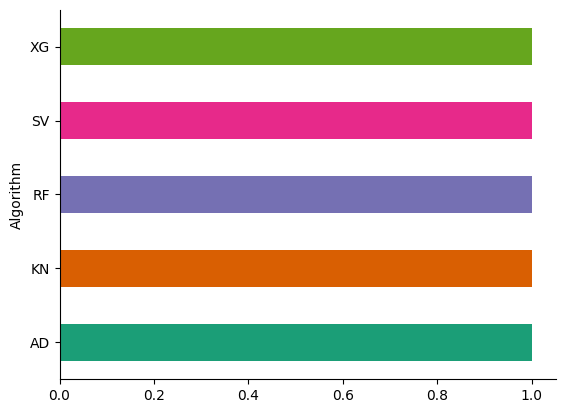

In [ ]:
performance_df.groupby('Algorithm').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)
performance_df

**Cross Validation**

In [ ]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import cross_val_score, GridSearchCV

models = [rf_model,svm_model,knn_model,ada_model,xgb_model]
features = X_std
labels=y
CV = 5
accu_list = []
ModelName = []
for model in models:
    model_name = model.__class__.__name__
    accuracies = cross_val_score(model, features, labels, scoring='accuracy', cv=CV)
    accu_list.append(accuracies.mean()*100)
    ModelName.append(model_name)

model_acc_df = pd.DataFrame({"Model" : ModelName, "Cross_Val_Accuracy" : accu_list})
model_acc_df

,Model,Cross_Val_Accuracy
0,RandomForestClassifier,98.980648
1,SVC,82.708653
2,KNeighborsClassifier,66.285188
3,AdaBoostClassifier,97.548796
4,XGBClassifier,98.778518


In [ ]:
model_acc_df.sort_values(by = ['Cross_Val_Accuracy'], ascending= False)

,Model,Cross_Val_Accuracy
0,RandomForestClassifier,98.980648
4,XGBClassifier,98.778518
3,AdaBoostClassifier,97.548796
1,SVC,82.708653
2,KNeighborsClassifier,66.285188
